<a href="https://colab.research.google.com/github/Nihar654/Data-Poisoning-in-Healthcare/blob/dev/Untitled8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install wfdb numpy matplotlib scipy scikit-learn imbalanced-learn pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 79.4 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstalled pandas-2.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.2 which is incompatible.
bqplot 0.12.45 requires pandas<3.0.0,>=1.0.0, but you have pandas 3.0.2 which is incompatible.
dask-cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.2 which is incompatible.
db-dtypes 1.5.1 requires pandas<3.0.0,>=1.5.3, but you have pandas 3.0.2 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but 

In [ ]:
# =============================================================================
# MIT-BIH Arrhythmia Dataset — Corrected Preprocessing Pipeline
# =============================================================================
# Fixes applied:
#   1. Bandpass filter applied to ALL records (not just one)
#   2. Per-beat normalization (not global)
#   3. Single normalization strategy (min-max only)
#   4. SMOTE result actually used downstream
#   5. Patient-wise train/test split (no data leakage)
#   6. Beat extraction done once, cleanly
#   7. Consistent label encoding (one method only)
#   8. stratify=y in train/test split
#   9. CSV saves the final, cleaned, normalized data
# =============================================================================

# ── Installs ──────────────────────────────────────────────────────────────────
# !pip install wfdb numpy matplotlib scipy scikit-learn imbalanced-learn pandas

import wfdb
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import butter, filtfilt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from collections import Counter

In [ ]:
# =============================================================================
# 1. CONFIGURATION
# =============================================================================

RECORDS = [
    '100','101','102','103','104','105','106','107','108','109',
    '111','112','113','114','115','116','117','118','119','121',
    '122','123','124','200','201','202','203','205','207','208',
    '209','210','212','213','214','215','217','219','220','221',
    '222','223','228','230','231','232','233','234'
]

VALID_LABELS = ['N', 'L', 'R', 'V', 'A']   # Normal + 4 arrhythmia types
WINDOW       = 180                           # samples before/after R-peak → 360 total
FS           = 360                           # MIT-BIH sampling frequency (Hz)
DATA_DIR     = './mitdb'

In [ ]:
# =============================================================================
# 2. BANDPASS FILTER  (0.5 – 40 Hz, applied per signal)
# =============================================================================

def bandpass_filter(signal, lowcut=0.5, highcut=40, fs=FS, order=3):
    """Zero-phase Butterworth bandpass filter."""
    nyquist = 0.5 * fs
    b, a = butter(order, [lowcut / nyquist, highcut / nyquist], btype='band')
    return filtfilt(b, a, signal)

In [ ]:
# =============================================================================
# 3. LOAD & FILTER ALL RECORDS
# =============================================================================

print("Loading and filtering records...")

raw_signals    = []   # filtered ECG lead-I signals
raw_anns       = []   # wfdb annotation objects

wfdb.dl_database('mitdb', DATA_DIR)

for r in RECORDS:
    record = wfdb.rdrecord(f'{DATA_DIR}/{r}')
    ann    = wfdb.rdann(f'{DATA_DIR}/{r}', 'atr')

    # FIX 1: filter EVERY record (previously only one was filtered)
    lead_signal = record.p_signal[:, 0]          # use Lead I
    filtered    = bandpass_filter(lead_signal)

    raw_signals.append(filtered)
    raw_anns.append(ann)

print(f"Loaded {len(raw_signals)} records.")

Loading and filtering records...
Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generat

In [ ]:
# =============================================================================
# 4. BEAT SEGMENTATION  (done ONCE, cleanly)
# =============================================================================

print("Segmenting beats...")

beats  = []
labels = []
record_ids = []   # track which record each beat came from (needed for proper split)

for i, (signal, ann) in enumerate(zip(raw_signals, raw_anns)):

    for j, r_peak in enumerate(ann.sample):

        sym = ann.symbol[j]

        if sym not in VALID_LABELS:
            continue                             # skip unwanted beat types

        start = r_peak - WINDOW
        end   = r_peak + WINDOW

        if start < 0 or end >= len(signal):
            continue                             # skip beats too close to edges

        beat = signal[start:end]                 # shape: (360,)
        beats.append(beat)
        labels.append(sym)
        record_ids.append(i)                     # store patient index

beats      = np.array(beats)       # (N, 360)
labels     = np.array(labels)
record_ids = np.array(record_ids)

print(f"Total beats extracted: {len(beats)}")
print(f"Class distribution: {Counter(labels)}")

Segmenting beats...
Total beats extracted: 100012
Class distribution: Counter({np.str_('N'): 75011, np.str_('L'): 8071, np.str_('R'): 7255, np.str_('V'): 7129, np.str_('A'): 2546})


In [ ]:
# =============================================================================
# 5. PER-BEAT NORMALIZATION  (min-max, per sample)
# =============================================================================
# FIX 2: normalize each beat independently so one outlier beat
#         doesn't compress the entire dataset.
# FIX 3: use ONE normalization method (min-max only).

beat_min = beats.min(axis=1, keepdims=True)   # shape: (N, 1)
beat_max = beats.max(axis=1, keepdims=True)

denom = beat_max - beat_min
denom[denom == 0] = 1e-8                       # avoid division by zero

X = (beats - beat_min) / denom                # values in [0, 1] per beat

print(f"X range after per-beat normalization: [{X.min():.4f}, {X.max():.4f}]")

X range after per-beat normalization: [0.0000, 1.0000]


Classes: [np.str_('A'), np.str_('L'), np.str_('N'), np.str_('R'), np.str_('V')]  →  [0, 1, 2, 3, 4]

Train beats: 79940  |  Test beats: 20072
Train class dist: Counter({np.int64(2): 56024, np.int64(1): 8071, np.int64(3): 7255, np.int64(4): 6329, np.int64(0): 2261})
Test  class dist: Counter({np.int64(2): 18987, np.int64(4): 800, np.int64(0): 285})

After SMOTE — Train class dist: Counter({np.int64(2): 56024, np.int64(0): 56024, np.int64(4): 56024, np.int64(1): 56024, np.int64(3): 56024})

Final shapes:
  X_train : (280120, 360, 1)
  X_test  : (20072, 360, 1)
  y_train : (280120,)
  y_test  : (20072,)


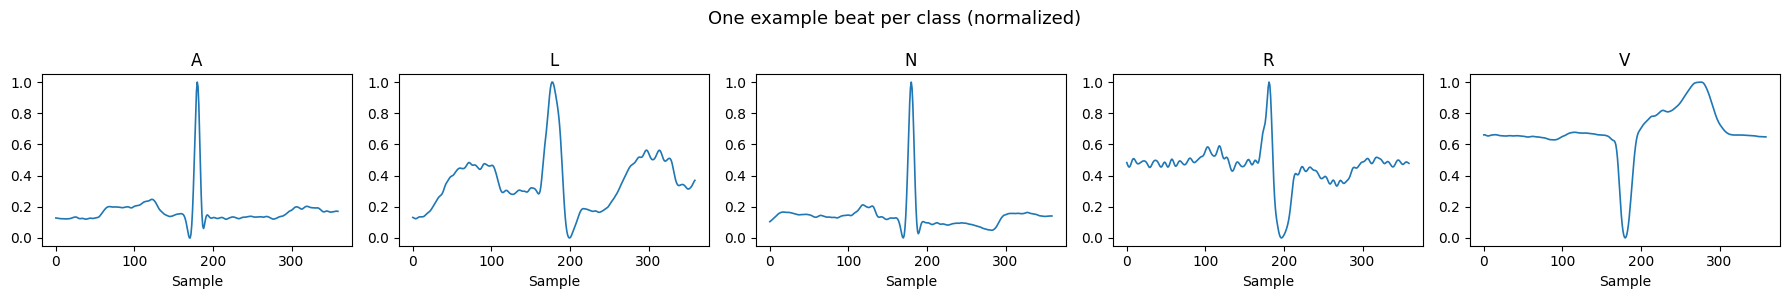


Saved → clean_mitbih_dataset.csv
          0         1         2         3         4         5         6  \
0  0.104301  0.107963  0.112342  0.117210  0.122046  0.126533  0.130807   
1  0.126065  0.135305  0.143501  0.150774  0.157133  0.162297  0.165974   
2  0.172178  0.181286  0.190191  0.197945  0.203894  0.208008  0.210890   
3  0.178874  0.184457  0.188747  0.192415  0.196085  0.199924  0.203739   
4  0.100627  0.106761  0.113783  0.121237  0.128511  0.135362  0.142127   

          7         8         9  ...       354       355       356       357  \
0  0.135278  0.140229  0.145510  ...  0.139690  0.140074  0.140605  0.141031   
1  0.168290  0.169897  0.171566  ...  0.141067  0.140966  0.140897  0.141302   
2  0.213394  0.216128  0.219176  ...  0.204634  0.205127  0.204672  0.202946   
3  0.207336  0.210671  0.213678  ...  0.180792  0.178205  0.174616  0.171477   
4  0.149389  0.157373  0.165579  ...  0.158566  0.156406  0.154851  0.153981   

        358       359  label  labe

In [ ]:


# =============================================================================
# 6. LABEL ENCODING  (one method only)
# =============================================================================
# FIX 4: use LabelEncoder consistently; drop the manual dict.

encoder = LabelEncoder()
y = encoder.fit_transform(labels)              # N → 0, L → 1, etc. (sorted)

print(f"Classes: {list(encoder.classes_)}  →  {list(range(len(encoder.classes_)))}")


# =============================================================================
# 7. PATIENT-WISE TRAIN / TEST SPLIT  (no data leakage)
# =============================================================================
# FIX 5: split by RECORD, not by individual beat.
#         Beats from the same patient must stay together.

unique_records = np.unique(record_ids)

train_records, test_records = train_test_split(
    unique_records,
    test_size=0.2,
    random_state=42
)

train_mask = np.isin(record_ids, train_records)
test_mask  = np.isin(record_ids, test_records)

X_train, y_train = X[train_mask], y[train_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]

print(f"\nTrain beats: {len(X_train)}  |  Test beats: {len(X_test)}")
print(f"Train class dist: {Counter(y_train)}")
print(f"Test  class dist: {Counter(y_test)}")


# =============================================================================
# 8. SMOTE ON TRAINING SET ONLY  (and actually use the result)
# =============================================================================
# FIX 6: apply SMOTE only to train split (never touch test set).
# FIX 7: use X_resampled / y_resampled going forward.

# Remove any classes with fewer than 2 samples (SMOTE requirement)
train_counts      = Counter(y_train)
valid_train_mask  = np.isin(y_train, [cls for cls, cnt in train_counts.items() if cnt >= 2])
X_train_f = X_train[valid_train_mask]
y_train_f = y_train[valid_train_mask]

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_f, y_train_f)

print(f"\nAfter SMOTE — Train class dist: {Counter(y_train_res)}")


# =============================================================================
# 9. RESHAPE FOR CNN  (samples, timesteps, channels)
# =============================================================================

X_train_cnn = X_train_res.reshape(-1, WINDOW * 2, 1)   # (N, 360, 1)
X_test_cnn  = X_test.reshape(-1, WINDOW * 2, 1)

print(f"\nFinal shapes:")
print(f"  X_train : {X_train_cnn.shape}")
print(f"  X_test  : {X_test_cnn.shape}")
print(f"  y_train : {y_train_res.shape}")
print(f"  y_test  : {y_test.shape}")


# =============================================================================
# 10. QUICK SANITY-CHECK PLOTS
# =============================================================================

fig, axes = plt.subplots(1, len(encoder.classes_), figsize=(18, 3))
fig.suptitle("One example beat per class (normalized)", fontsize=13)

for cls_idx, cls_name in enumerate(encoder.classes_):
    idx = np.where(y_train_res == cls_idx)[0][0]
    axes[cls_idx].plot(X_train_res[idx], linewidth=1.2)
    axes[cls_idx].set_title(cls_name)
    axes[cls_idx].set_xlabel("Sample")
    axes[cls_idx].set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.savefig("beat_examples.png", dpi=120)
plt.show()


# =============================================================================
# 11. SAVE CLEANED DATASET
# =============================================================================
# FIX 8: save the FINAL normalized data (train + test combined, pre-SMOTE)
#         so the CSV reflects real, unaugmented samples.

df = pd.DataFrame(X)                                    # original normalized beats
df['label']      = labels                               # string label ('N','V',...)
df['label_enc']  = y                                    # integer label
df['record_id']  = record_ids                           # which patient
df['split']      = np.where(train_mask, 'train', 'test')

df.to_csv("clean_mitbih_dataset.csv", index=False)
print("\nSaved → clean_mitbih_dataset.csv")
print(df.head())

In [ ]:
import torch

# Add channel dimension (VERY IMPORTANT)
X_train_torch = torch.tensor(X_train_res, dtype=torch.float32).unsqueeze(1)
X_test_torch  = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)

y_train_torch = torch.tensor(y_train_res, dtype=torch.long)
y_test_torch  = torch.tensor(y_test, dtype=torch.long)

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_torch, y_train_torch)
test_dataset  = TensorDataset(X_test_torch, y_test_torch)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=32)

In [ ]:
import torch.nn as nn

class ECG_CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv1d(1, 16, kernel_size=5)
        self.pool = nn.MaxPool1d(2)

        self.conv2 = nn.Conv1d(16, 32, kernel_size=5)

        # Dynamically calculate size
        self._to_linear = None
        self._get_conv_output()

        self.fc1 = nn.Linear(self._to_linear, 64)
        self.fc2 = nn.Linear(64, 5)  # 5 classes

    def _get_conv_output(self):
        x = torch.randn(1, 1, 360)
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        self._to_linear = x.numel()

    def forward(self, x):

        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))

        x = x.view(x.size(0), -1)

        x = torch.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ECG_CNN().to(device)

In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
epochs = 15

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Forward pass
        outputs = model(X_batch)

        # Compute loss
        loss = criterion(outputs, y_batch)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss:.4f}")

Epoch 1/15, Loss: 829.4154
Epoch 2/15, Loss: 163.0498
Epoch 3/15, Loss: 99.3368
Epoch 4/15, Loss: 72.3983
Epoch 5/15, Loss: 54.4726
Epoch 6/15, Loss: 42.9065
Epoch 7/15, Loss: 38.8167
Epoch 8/15, Loss: 32.5755
Epoch 9/15, Loss: 28.9940
Epoch 10/15, Loss: 26.4210
Epoch 11/15, Loss: 21.7868
Epoch 12/15, Loss: 20.7445
Epoch 13/15, Loss: 20.0622
Epoch 14/15, Loss: 17.4798
Epoch 15/15, Loss: 16.3340


In [ ]:
model.eval()

correct = 0
total = 0

all_preds = []
all_labels = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model(X_batch)

        _, predicted = torch.max(outputs, 1)

        total += y_batch.size(0)
        correct += (predicted == y_batch).sum().item()

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

accuracy = correct / total

print("Test Accuracy:", accuracy)

Test Accuracy: 0.8823236349143085
